In [2]:
import torch 

words = open("names.txt", "r").read().splitlines()

N = torch.zeros((27, 27), dtype = torch.int32)

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi["."] = 0

itos = {i:s for s, i in stoi.items()}

In [3]:

for w in words: 
    chs = ["."] + list(w) + ["."]
    
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1
        
    #    print(ch1, ch2)

#print(b)
#print(N)

AxesImage(shape=(27, 27))


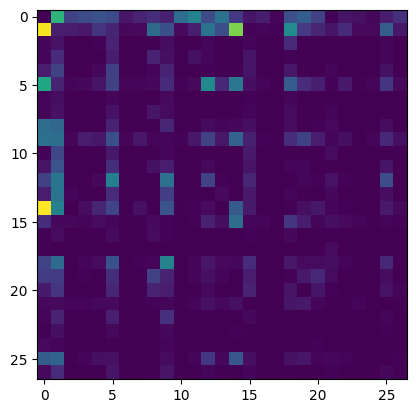

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline
print(plt.imshow(N))

In [6]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()

print(p)

torch.multinomial(p, num_samples=20, replacement=True, generator=g)

tensor([0.6064, 0.3033, 0.0903])


tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1])

In [7]:
P = N.float()
P /= P.sum(1, keepdim=True)

#print(P)
#P.sum(1)

In [8]:
g = torch.Generator().manual_seed(2147483647)

for i in range(5):

    out = []
    ix = 0 
    while True:

        p = P[ix]

        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])

        if ix == 0:
            break

    print("".join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.


In [9]:
log_likelihood = 0.0 
n = 0 

for w in words: 
    chs = ["."] + list(w) + ["."]
    
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1 
        #print(f"{ch1}{ch2}: {prob:.4f} {logprob:.4f}")
        
    #    print(ch1, ch2)

print(f"{log_likelihood=}")
nll = -log_likelihood
print(f"{nll=}")
print(f"{nll/n}")
#print(b)
#print(N)

log_likelihood=tensor(-559891.7500)
nll=tensor(559891.7500)
2.454094171524048


In [10]:
xs, ys = [], []

for w in words[:1]: 
    chs = ["."] + list(w) + ["."]
    
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

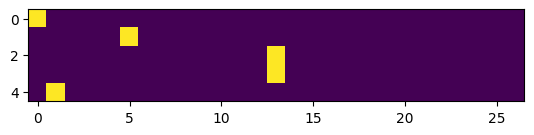

In [11]:
import torch.nn.functional as F 
xenc = F.one_hot(xs, num_classes=27).float()

plt.imshow(xenc)

In [56]:
g = torch.Generator().manual_seed(2147483647)
W = torch.rand((27, 27), generator=g, requires_grad=True)

In [57]:
print(xs)

tensor([ 0,  5, 13, 13,  1])


In [79]:
xenc = F.one_hot(xs, num_classes=27).float()
logits = xenc @ W
counts = logits.exp()

probs = counts / counts.sum(1, keepdims = True)
loss = -probs[torch.arange(5), ys].log().mean()
print(loss.item())

3.347058057785034


In [80]:
W.grad = None 
loss.backward()

In [81]:
W.data += -0.1 * W.grad

In [82]:
print(loss)

tensor(3.3471, grad_fn=<NegBackward0>)


In [98]:
xs, ys = [], []

for w in words: 
    chs = ["."] + list(w) + ["."]
    
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()

print("Number of examples: ", num)

Number of examples:  228146


In [99]:
g = torch.Generator().manual_seed(2147483647)
W = torch.rand((27, 27), generator=g, requires_grad=True)

In [103]:
iter = 100 

for k in range(iter):
    
    xenc = F.one_hot(xs, num_classes=27).float()

    logits = xenc @ W
    counts = logits.exp()

    probs = counts / counts.sum(1, keepdims = True)
    loss = -probs[torch.arange(num), ys].log().mean()
    
    print(loss.item())


    W.grad = None 
    loss.backward()
    W.data += -50 * W.grad

2.4704153537750244
2.470238447189331
2.470064878463745
2.4698948860168457
2.4697282314300537
2.4695651531219482
2.469404697418213
2.469247817993164
2.4690937995910645
2.468942642211914
2.468794345855713
2.468648910522461
2.468506097793579
2.4683661460876465
2.468228340148926
2.4680933952331543
2.4679605960845947
2.4678304195404053
2.4677021503448486
2.467576026916504
2.4674525260925293
2.4673311710357666
2.4672117233276367
2.4670941829681396
2.4669790267944336
2.4668655395507812
2.4667539596557617
2.466644525527954
2.466536283493042
2.4664299488067627
2.466325283050537
2.4662225246429443
2.4661214351654053
2.466021776199341
2.46592378616333
2.465827226638794
2.4657318592071533
2.4656388759613037
2.465546131134033
2.4654552936553955
2.4653658866882324
2.465277910232544
2.465191125869751
2.4651050567626953
2.4650213718414307
2.4649384021759033
2.4648563861846924
2.464775323867798
2.464695930480957
2.4646174907684326
2.4645402431488037
2.464463710784912
2.464388847351074
2.464314222335815